# Workshop 3: Componentes de una serie de tiempo y Random Walk
## Modelando el SP500 como random walk

## Fase inicial

Importamos las librerías necesarias para el manejo de los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from io import BytesIO

Descargamos el dataset mensual con el volumen de las ventas de marcas grandes de una categoría consumidor-producto y guardamos los datos de `resultado` en un dataframe de pandas.

In [2]:
url = "http://www.apradie.com/ec2004/salesbrands3.xlsx"
# Algunos servidores rechazan peticiones que no parecen venir de un navegador:
headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0 Safari/537.36'}
response = requests.get(url, headers=headers)
response.raise_for_status()
sales_brand = pd.read_excel(BytesIO(response.content), sheet_name='Resultado')

Ahora preparamos el dataset para que pandas pueda leerlo, primero convertimos texto de fechas a un formato de fechas, después hacemos que el index de cada fila sea la fecha y que se ordene ya que el orden importa y lo hacemos de manera mensual.

In [3]:
sales_brand['date'] = pd.to_datetime(sales_brand['date'])
sales_brand = sales_brand.set_index('date').sort_index().asfreq('MS')
sales_brand.head()

,qbrand1tons,salesbrand1,qbrand2tons,salesbrand2,qbrand3tons,salesbrand3,qbrand4tons,salesbrand4,qbrand5tons,salesbrand5,qbrand6tons,salesbrand6,tonstotal,salestotal
date,,,,,,,,,,,,,,
2015-01-01,106.62,60780.72,195.46,60700.51,293.10,75196.35,185.91,48228.51,28.94,2295.50,338.38,55561.26,1148.41,302762.85
2015-02-01,105.82,60411.47,216.09,68289.15,494.46,105010.90,149.30,39922.14,24.66,1973.43,284.52,51469.74,1274.85,327076.83
2015-03-01,88.82,53174.89,220.15,62529.54,356.88,90902.84,144.65,39788.22,23.75,1903.24,251.34,50395.48,1085.59,298694.21
2015-04-01,86.69,50861.69,170.74,50575.68,291.07,72853.34,161.43,42692.59,21.00,1684.28,230.29,49124.61,961.22,267792.19
2015-05-01,87.23,51014.23,177.17,54327.48,318.09,75277.10,141.09,37167.52,23.44,1883.41,250.45,46906.63,997.47,266576.37


Una serie de tiempo es una cosa medida una y otra vez en intervalos regulares, el orden de los datos importa ya que en modelos de IA de Machine Learning normalmente se randomizan los datos y se hace un split de ellos, en este dataset haríamos trampa si aplicamos lo que comúnmente se hace ya que podría entrenar con datos del futuro y predecir los del pasado, esto sería imposible ya que en la vida real no cuentas con datos del futuro.

## Componentes de una serie de tiempo

Una serie de tiempo normalmente tiene 4 componentes:

1. Tendencia (trend): el movimiento de largo plazo hacia arriba o hacia abajo.
2. Estacionalidad (seasonality): un patrón que se repite cada cierto periodo fijo (cada año, cada semana) por ejemplo más ventas en diciembre.
3. Ciclos (cycles): subidas y bajadas de más de un año pero sin un periodo fijo como las recesiones son difíciles de predecir porque cambia su duración.
4. Irregular o residuo (remainder): los choques aleatorios que no se pueden predecir con media cero.

La tendencia y la estacionalidad son lo más fácil de modelar el residuo por definición es impredecible.

Graficamos las toneladas vendidas de la marca 6 para ver qué componentes aparecen a simple vista.

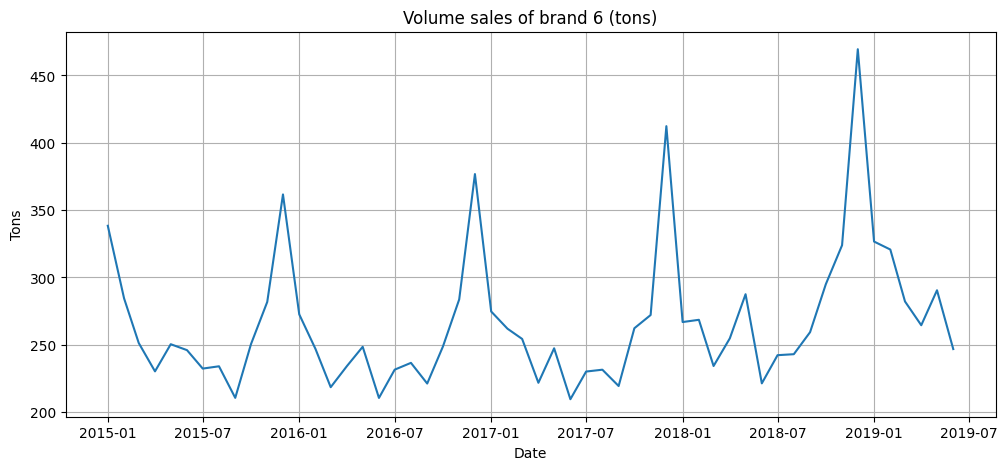

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(sales_brand.index, sales_brand['qbrand6tons'])
plt.title('Volume sales of brand 6 (tons)')
plt.xlabel('Date')
plt.ylabel('Tons')
plt.grid(True)
plt.show()

En la gráfica vemos una tendencia creciente ya que con los años la marca 6 vende más toneladas, también vemos picos y caídas que se repiten más o menos en los mismos meses cada año lo que indica estacionalidad.

Para separar estos componentes de forma formal usamos una descomposición.

### Descomposición STL

Usamos la descomposición STL (Seasonal-Trend decomposition using LOESS), que separa la serie en tres partes que sumadas dan la serie original, la tendencia más la estacionalidad más el residuo.

La aplicamos al logaritmo de las ventas y no a las ventas directas, STL supone que los componentes se suman, pero en ventas el efecto estacional suele ser un porcentaje por ejemplo diciembre vende 20% más que el promedio y con el logaritmo ese efecto porcentual se vuelve una suma constante lo cual es lo que STL necesita.

Usamos `period=12` porque los datos son mensuales y el patrón se repite cada 12 meses y `robust=True` para que los valores atípicos no distorsionen la tendencia ni la estacionalidad.

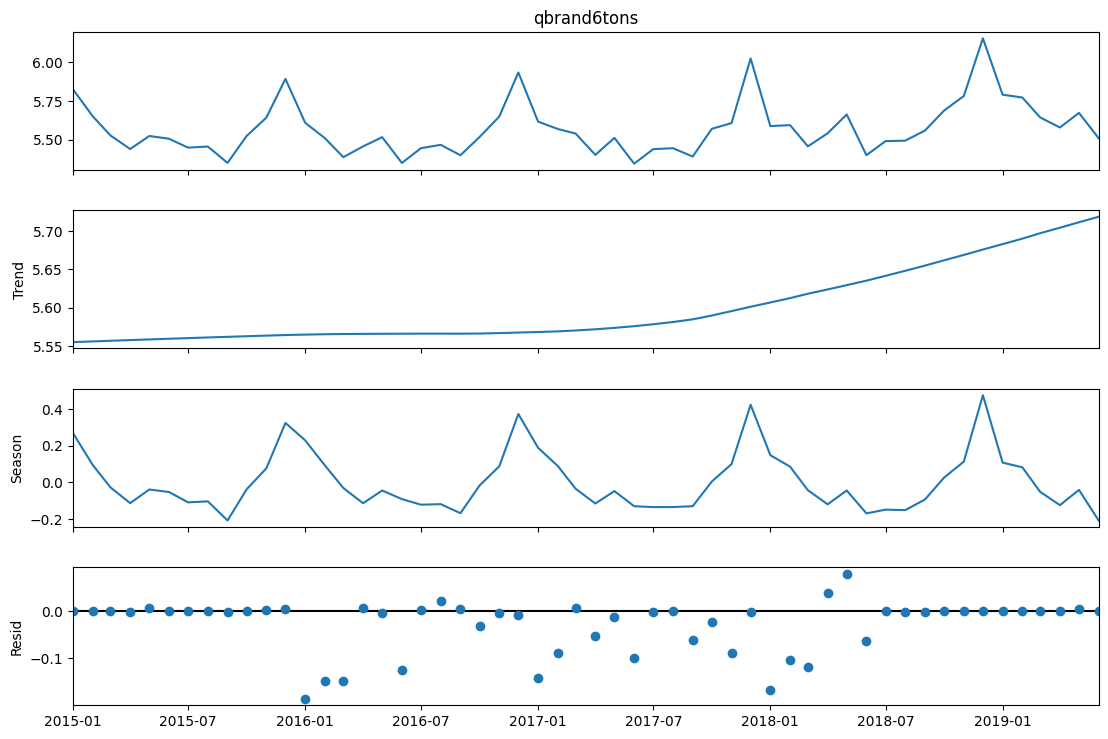

In [6]:
from statsmodels.tsa.seasonal import STL

log_q6 = np.log(sales_brand['qbrand6tons'])
stl_q6 = STL(log_q6, period=12, robust=True).fit()

fig = stl_q6.plot()
fig.set_size_inches(12, 8)
plt.show()

La gráfica tiene 4 paneles:

1. La serie original en logaritmos.
2. La tendencia de largo plazo de las ventas.
3. El patrón que se repite cada 12 meses.
4. Lo que queda después de quitar la tendencia y la estacionalidad, o sea el componente irregular que no se puede predecir.

### Fuerza de la tendencia y de la estacionalidad

Para medir qué tan fuerte es cada componente comparamos la varianza del residuo contra la varianza del componente más el residuo (Hyndman y Athanasopoulos, 2021), la fuerza de la tendencia es 1 menos la varianza del residuo entre la varianza de la tendencia más el residuo y la fuerza de la estacionalidad se calcula igual pero con la estacionalidad en lugar de la tendencia, si el resultado sale negativo se toma como 0.

Si el residuo es muy pequeño comparado con el componente el cociente es casi 0 y la fuerza es casi 1 (componente fuerte) y si el residuo es igual de grande que el componente la fuerza es casi 0 (componente débil).

In [7]:
R = stl_q6.resid
F_trend = max(0, 1 - R.var() / (stl_q6.trend + R).var())
F_seas = max(0, 1 - R.var() / (stl_q6.seasonal + R).var())
print(f"Strength of trend:       {F_trend:.3f}")
print(f"Strength of seasonality: {F_seas:.3f}")

Strength of trend:       0.523
Strength of seasonality: 0.875


Para la marca 6 la fuerza de la tendencia es 0.523 y la de la estacionalidad es 0.875.

La estacionalidad es fuerte ya que el patrón anual explica gran parte del movimiento de las ventas y la tendencia es moderada porque sí existe un crecimiento, pero el residuo todavía tiene un peso importante comparado con ella.

El residuo es lo que hace que una serie sea en parte impredecible, el modelo más simple donde todo es residuo (excepto una deriva constante) es la siguiente caminata aleatoria (random walk) que vemos.

## El modelo de caminata aleatoria (random walk)

La hipótesis de caminata aleatoria en finanzas (Fama, 1965) dice que el logaritmo del precio de una acción se comporta como una caminata aleatoria con deriva, o sea que el log precio de hoy es igual a una deriva constante más el log precio de ayer más un choque aleatorio, donde los choques siguen una distribución normal con media cero y una desviación estándar fija.

1. Choque (shock): el efecto neto de todas las noticias del día sobre el logaritmo del precio, tiene media cero y los choques de distintos días son independientes.
2. Deriva (drift): si es positiva la serie tiende a crecer, si es negativa tiende a bajar y si es cero tenemos una caminata aleatoria sin deriva.
3. Volatilidad (volatility): la desviación estándar de los choques, o sea qué tanto varían de un día a otro.

### ¿Qué es predecible y qué no?

Si pasamos el log precio de ayer al otro lado de la ecuación nos queda que el log precio de hoy menos el de ayer es igual a la deriva más el choque.

Esa diferencia de logaritmos es el rendimiento logarítmico (log return) diario, entonces el rendimiento de cada día es una constante más un choque aleatorio por lo que no podemos predecir el rendimiento de mañana más allá de su media, por otro lado el nivel sí tiene un mejor pronóstico que es el log precio de hoy más la deriva por eso a la caminata aleatoria también se le llama pronóstico ingenuo (naive forecast) y lo que no podemos saber es qué tan lejos de ese pronóstico va a quedar el valor real.

### Valor después de N periodos

Si sustituimos la ecuación día por día desde un valor inicial llegamos a que el valor después de N días es el valor inicial más N veces la deriva más la suma de todos los choques de esos N días.

Si pudiéramos repetir la historia muchas veces desde el mismo valor inicial (cada repetición es una trayectoria o path) y como los choques tienen media cero el valor esperado es el valor inicial más N veces la deriva y como los choques son independientes y tienen la misma varianza sus varianzas se suman entonces la varianza después de N días es N veces la varianza del choque y la desviación estándar es la raíz de N por la volatilidad diaria.

Esta es la regla de la raíz cuadrada del tiempo (square-root-of-time rule) y nos dice que la incertidumbre crece con la raíz de N y no con N, por ejemplo a un año (252 días hábiles) la incertidumbre es la raíz de 252 que es alrededor de 15.9 veces la de un día y no 252 veces.

Hay que tener cuidado porque esta varianza es entre muchas historias posibles y del S&P 500 solo observamos una, además la desviación estándar de los log precios a lo largo del tiempo no tiene significado ya que la caminata aleatoria no es estacionaria (stationary) por eso los parámetros se estiman con los rendimientos y no con los log precios.

### Cómo estimar los parámetros

Como el rendimiento diario es la deriva más un choque con media cero la deriva se estima con la media de los rendimientos logarítmicos diarios y la volatilidad con su desviación estándar además si tenemos N precios tenemos N-1 rendimientos y al sacar la media los términos de en medio se cancelan, entonces la deriva también se puede calcular como el último log precio menos el primero entre N-1.

## El S&P 500 como caminata aleatoria

Descargamos el precio de cierre diario del índice S&P 500 (`^GSPC`) de Yahoo Finance desde 2008 hasta septiembre de 2026, usamos `auto_adjust=True` para que los precios estén ajustados, `squeeze()` para que quede como serie y no como tabla y `dropna()` para quitar los días sin dato.

In [8]:
import yfinance as yf

sp500 = yf.download("^GSPC", start="2008-01-01", end="2026-09-30",
                    auto_adjust=True, progress=False)['Close'].squeeze().dropna()
sp500.name = 'SP500'
sp500.tail()

,SP500
Date,
2026-09-23,7706.029785
2026-09-24,7704.129883
2026-09-25,7743.410156
2026-09-28,7683.689941
2026-09-29,7670.839844


El último dato es el 29 de septiembre de 2026 ya que en `yf.download` la fecha de `end` no se incluye.

Dividimos los datos en dos partes como en un ejercicio real de pronóstico, el periodo de entrenamiento (training) de 2008 a 2025 sirve para estimar el modelo y el periodo de prueba (test) de 2026 sirve para revisar qué tan bueno es el pronóstico con datos que el modelo nunca vio. Después sacamos los rendimientos logarítmicos diarios con `diff()` que resta el log precio de hoy menos el de ayer y los graficamos.

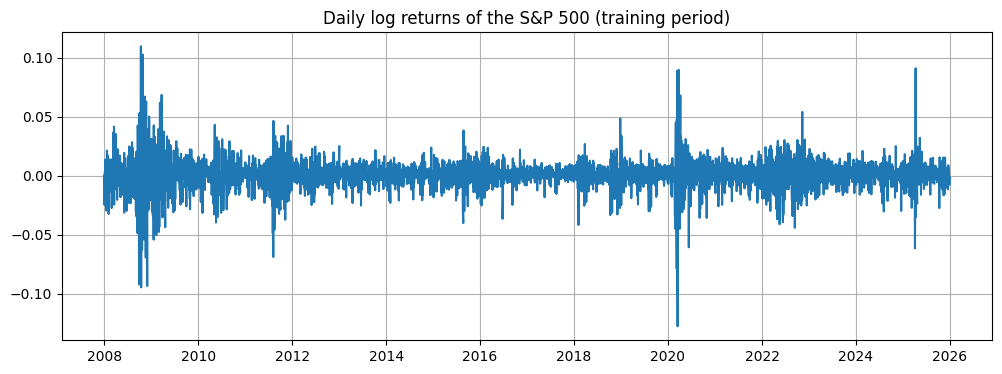

In [9]:
lnsp = np.log(sp500)
ln_train = lnsp[:'2025-12-31']
ln_test = lnsp['2026-01-01':]

r_train = ln_train.diff().dropna()   # rendimientos logarítmicos diarios

plt.figure(figsize=(12, 4))
plt.plot(r_train.index, r_train)
plt.title('Daily log returns of the S&P 500 (training period)')
plt.grid(True)
plt.show()

El log precio tiene una tendencia clara, pero los rendimientos tienen alrededor de una media constante muy cercana a cero, también vemos agrupamiento de volatilidad (volatility clustering) ya que hay periodos tranquilos y periodos muy distorsionados como 2008-2009 y 2020 (por las crisis de esos años) y la caminata aleatoria básica supone que la volatilidad es constante así que no captura esto y es una de sus limitaciones.

### Autocorrelación de los rendimientos

La autocorrelación (autocorrelation) es la correlación de una serie con su propio valor pasado, si la hipótesis de caminata aleatoria se cumple el rendimiento de hoy no debería estar correlacionado con el de ayer así que calculamos la autocorrelación de rezago 1 (lag-1) de los rendimientos diarios.

In [10]:
ac1 = float(r_train.autocorr(lag=1))
ac1

-0.1209315681186538

La autocorrelación es de -0.121 y el workshop la considera muy cercana a cero o sea que el rendimiento de ayer casi no nos dice nada sobre el de hoy lo cual es consistente con la caminata aleatoria, pero como tenemos más de 4,500 rendimientos el límite aproximado para considerarla distinta de cero es de más o menos 2 entre la raíz de n que da alrededor de 0.03 por lo que -0.121 sí es estadísticamente distinta de cero y aun así es una relación débil y negativa que indica que después de un día de subida tiende a haber una pequeña corrección y viceversa.

### Estimación de los parámetros

Ahora estimamos los parámetros con los rendimientos, `phi0` es la media y `sigma` la desviación estándar, `y0` es el primer log precio del entrenamiento (2 de enero de 2008) y `N` es el número de días del entrenamiento, también comprobamos que la media de los rendimientos coincide con la fórmula de último menos primero entre N-1.

In [11]:
phi0 = float(r_train.mean())
sigma = float(r_train.std())
y0 = float(ln_train.iloc[0])
N = len(ln_train)

# Comprobación: la media de los rendimientos es igual a (último - primero)/(número de rendimientos)
phi0_check = float((ln_train.iloc[-1] - ln_train.iloc[0]) / (N - 1))
print(f"phi0  = {phi0:.6f}   (check: {phi0_check:.6f})")
print(f"sigma = {sigma:.6f}")

phi0  = 0.000343   (check: 0.000343)
sigma = 0.012658


La deriva diaria estimada es 0.000343 y la volatilidad diaria es 0.012658, las dos formas de calcular la deriva dan lo mismo así que la comprobación funciona, si lo pasamos a términos anuales con 252 días hábiles la deriva es 0.000343 por 252 que es alrededor de 8.6% y la volatilidad es 0.012658 por la raíz de 252 que es alrededor de 20.1% la volatilidad se multiplica por la raíz de 252 y no por 252 por la regla de la raíz cuadrada del tiempo.

### Simulación de una trayectoria

Simulamos una posible trayectoria de la caminata aleatoria que empieza en el primer log precio de 2008 y dura los mismos N días del entrenamiento, primero generamos los choques diarios con media 0 y desviación estándar `sigma` y después aplicamos la ecuación del modelo día por día con un ciclo `for` y por último usamos una semilla (seed) para que los números aleatorios salgan iguales cada vez que corremos el código.

In [12]:
# semilla para que los números aleatorios se puedan reproducir
rng = np.random.default_rng(1)
# choques diarios con media 0 y desviación estándar sigma (calculada con los rendimientos)
shocks = rng.normal(0, sigma, N)

# vector de N ceros donde guardamos la trayectoria
rw1 = np.zeros(N)
# el día 0 es el primer log precio del entrenamiento (2 de enero de 2008)
rw1[0] = y0
# aplicamos la ecuación del modelo desde el día 1 hasta el último día de 2025
for t in range(1, N):
    rw1[t] = phi0 + rw1[t-1] + shocks[t]

También podemos hacer lo mismo sin ciclo ya que el valor de cada día es el valor inicial más la suma de las derivas y los choques hasta ese día es por eso que usamos la suma acumulada `np.cumsum` de la deriva más los choques y ponemos el primer paso en 0 porque el día 0 es el valor inicial y al final comprobamos con `np.allclose` que las dos trayectorias son iguales.

In [13]:
steps = phi0 + shocks
steps[0] = 0                          # el día 0 no tiene choque
rw1_vec = y0 + np.cumsum(steps)
print(np.allclose(rw1, rw1_vec))      # los dos métodos dan la misma trayectoria

True


Ahora simulamos una caminata aleatoria sin deriva (deriva igual a 0) usando los mismos choques para ver qué papel tiene la deriva y graficamos las dos trayectorias junto con el log real del S&P 500.

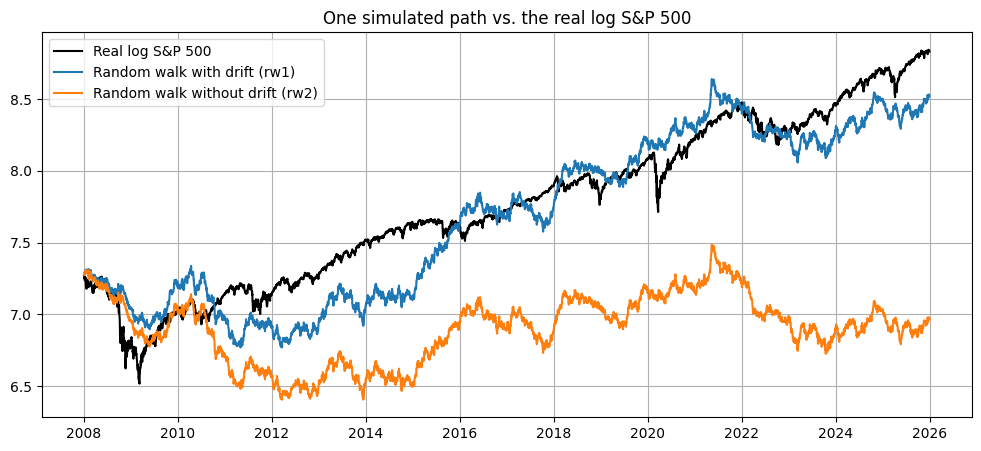

In [14]:
# mismos choques pero sin sumar la deriva (phi0 = 0)
steps0 = shocks.copy()
steps0[0] = 0
rw2 = y0 + np.cumsum(steps0)

plt.figure(figsize=(12, 5))
plt.plot(ln_train.index, ln_train, color='black', label='Real log S&P 500')
plt.plot(ln_train.index, rw1, label='Random walk with drift (rw1)')
plt.plot(ln_train.index, rw2, label='Random walk without drift (rw2)')
plt.title('One simulated path vs. the real log S&P 500')
plt.legend()
plt.grid(True)
plt.show()

En esta simulación la trayectoria con deriva termina arriba de donde empezó pero por debajo del S&P 500 real y la trayectoria sin deriva termina incluso por debajo de su valor inicial y la única diferencia entre las dos es la deriva así que eso muestra cuánto pesa a lo largo de muchos años.

Una sola trayectoria no nos dice mucho ya que si cambiamos la semilla la trayectoria cambia por completo, o sea que una trayectoria no es un pronóstico sino solo una historia posible, para saber lo que realmente dice el modelo necesitamos muchas trayectorias y eso es una simulación Monte Carlo.

### Simulación Monte Carlo

Simulamos 1,000 trayectorias para todo el periodo de entrenamiento, cada fila de la matriz es una historia posible y cada columna es un día, `axis=1` hace que la suma acumulada se haga a lo largo de los días de cada trayectoria.

In [15]:
n_paths = 1000
rng = np.random.default_rng(123)
step_matrix = phi0 + rng.normal(0, sigma, size=(n_paths, N))
step_matrix[:, 0] = 0                          # día 0 = y0 para todas las trayectorias
paths = y0 + np.cumsum(step_matrix, axis=1)    # una trayectoria por fila

Para cada día calculamos los percentiles 5, 50 y 95 entre las 1,000 trayectorias y con eso hacemos una gráfica de abanico (fan chart), la banda entre el percentil 5 y el 95 es donde el modelo espera que esté la serie el 90% del tiempo y la mediana es la trayectoria del centro además dibujamos 20 trayectorias en gris para ver cómo se ven individualmente.

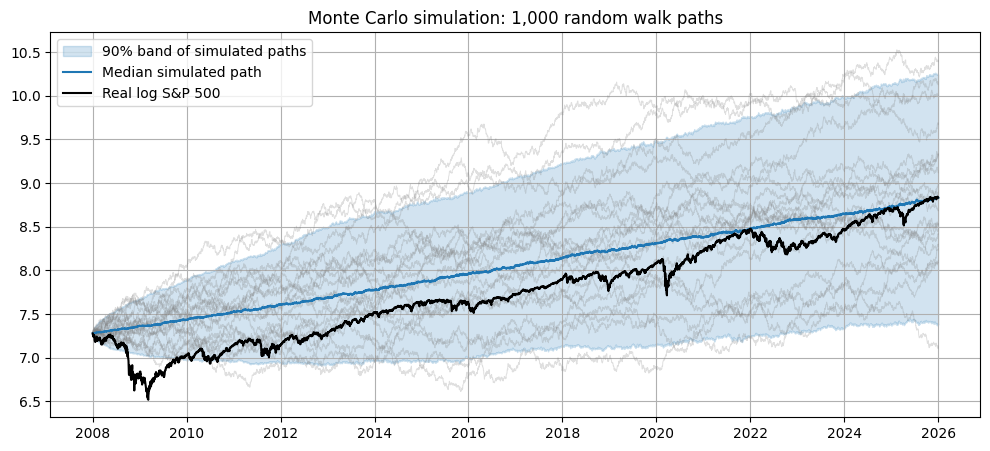

In [16]:
p05, p50, p95 = np.percentile(paths, [5, 50, 95], axis=0)

plt.figure(figsize=(12, 5))
for i in range(20):
    plt.plot(ln_train.index, paths[i], color='grey', alpha=0.25, linewidth=0.7)
plt.fill_between(ln_train.index, p05, p95, color='tab:blue', alpha=0.2, label='90% band of simulated paths')
plt.plot(ln_train.index, p50, color='tab:blue', label='Median simulated path')
plt.plot(ln_train.index, ln_train, color='black', label='Real log S&P 500')
plt.title('Monte Carlo simulation: 1,000 random walk paths')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

Calculamos qué porcentaje de los días el S&P 500 real quedó dentro de la banda del 90%.

In [17]:
inside = float(np.mean((ln_train.values >= p05) & (ln_train.values <= p95)))
print(f"Days inside the 90% band: {inside:.1%}")

Days inside the 90% band: 93.4%


El S&P 500 real queda dentro de la banda del 90% el 93.4% de los días, o sea que la serie real se comporta como si fuera una trayectoria más de la caminata aleatoria.

### La regla de la raíz cuadrada del tiempo

La banda del abanico se hace más ancha con el tiempo, para comprobar la regla de la raíz cuadrada del tiempo comparamos la desviación estándar entre las 1,000 trayectorias en cada día contra el valor teórico el cual es la volatilidad diaria por la raíz del número de días.

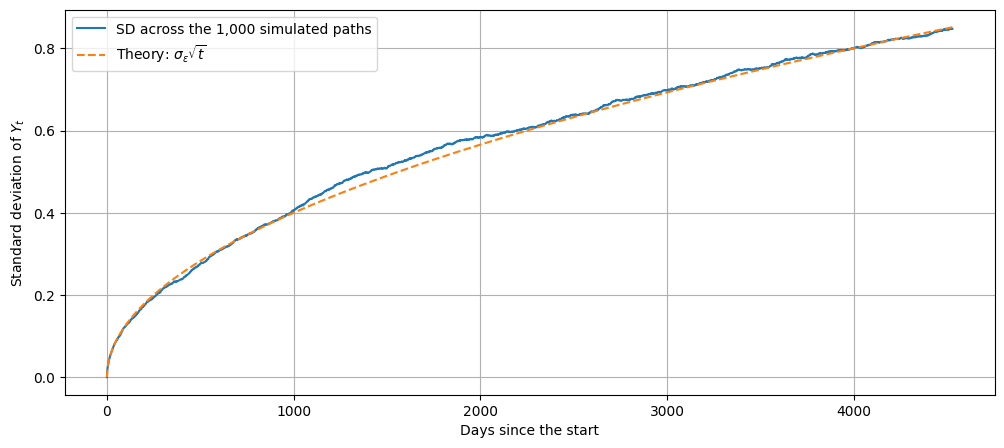

In [18]:
t_idx = np.arange(N)
sd_across = paths.std(axis=0)

plt.figure(figsize=(12, 5))
plt.plot(t_idx, sd_across, label='SD across the 1,000 simulated paths')
plt.plot(t_idx, sigma * np.sqrt(t_idx), '--', label=r'Theory: $\sigma_\varepsilon\sqrt{t}$')
plt.xlabel('Days since the start')
plt.ylabel('Standard deviation of $Y_t$')
plt.legend()
plt.grid(True)
plt.show()

Las dos curvas casi se enciman lo que confirma que la varianza crece en proporción al número de días y la desviación estándar con la raíz del número de días.

Las pequeñas diferencias de la curva simulada son porque solo usamos 1,000 trayectorias.

## Pronóstico con la caminata aleatoria

Ahora usamos el modelo como herramienta de pronóstico estando en el último día de 2025 queremos saber qué dice la caminata aleatoria sobre 2026.

La respuesta analítica para h días hacia adelante es que el log precio sigue una distribución normal con media igual al último valor más h veces la deriva y varianza igual a h veces la varianza del choque.

También podemos obtenerla con Monte Carlo que es lo que se sigue usando cuando los modelos son más complejos y ya no hay una fórmula sencilla.

Simulamos 5,000 trayectorias que empiezan en `yT` el último log precio de 2025 y duran `h` días que son los días hábiles que tenemos en el periodo de prueba de 2026, después calculamos los percentiles 5, 50 y 95 de cada día y los regresamos a escala de precio con `np.exp` para graficarlos junto con el precio real de 2024-2025 y lo que realmente pasó en 2026.

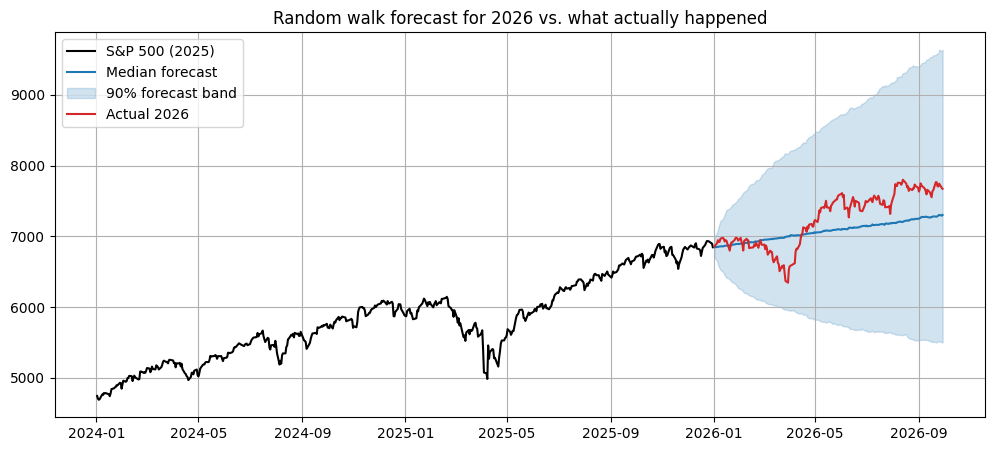

In [19]:
yT = float(ln_train.iloc[-1])
h = len(ln_test)

rng = np.random.default_rng(2026)
fc_paths = yT + np.cumsum(phi0 + rng.normal(0, sigma, size=(5000, h)), axis=1)
f05, f50, f95 = np.percentile(fc_paths, [5, 50, 95], axis=0)

plt.figure(figsize=(12, 5))
plt.plot(sp500['2024-01-01':'2025-12-31'], color='black', label='S&P 500 (2025)')
plt.plot(ln_test.index, np.exp(f50), color='tab:blue', label='Median forecast')
plt.fill_between(ln_test.index, np.exp(f05), np.exp(f95), color='tab:blue', alpha=0.2, label='90% forecast band')
plt.plot(sp500['2026-01-01':], color='tab:red', label='Actual 2026')
plt.title('Random walk forecast for 2026 vs. what actually happened')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

En la gráfica la banda del 90% se abre conforme avanzan los días de 2026 ya que la incertidumbre crece con la raíz del número de días, el precio real de 2026 (línea roja) se queda dentro de la banda y la mediana del pronóstico solo sube poco a poco por la deriva positiva.

Ahora respondemos algunas preguntas con la simulación y las comparamos con la fórmula analítica.

1. Probabilidad de que el S&P 500 termine el periodo arriba del cierre de 2025. Con Monte Carlo es la proporción de trayectorias cuyo último valor es mayor a `yT` y con la fórmula es la normal acumulada (`norm.cdf`) de h por la deriva entre la volatilidad por la raíz de h, o sea qué tan grande es la deriva acumulada comparada con la incertidumbre acumulada.
2. Banda del 90% para el último día. Los percentiles 5 y 95 de los valores finales simulados en escala de precio.
3. Percentil del valor real. La proporción de trayectorias que terminaron por debajo del valor real del último día.

In [20]:
from scipy.stats import norm

end_sim = fc_paths[:, -1]
actual_end = float(ln_test.iloc[-1])

p_up_mc = float(np.mean(end_sim > yT))
p_up_theory = float(norm.cdf(h * phi0 / (sigma * np.sqrt(h))))
band_low, band_high = np.exp(np.percentile(end_sim, [5, 95]))
pct_actual = float(np.mean(end_sim < actual_end))

print(f"Trading days in the forecast: {h}")
print(f"P(S&P ends 2026 above its end-2025 level): MC = {p_up_mc:.3f}, theory = {p_up_theory:.3f}")
print(f"90% band for the end-2026 level: {band_low:,.0f} to {band_high:,.0f}")
print(f"Actual end-2026 level: {np.exp(actual_end):,.0f}  (percentile within the simulation: {pct_actual:.2f})")

Trading days in the forecast: 186
P(S&P ends 2026 above its end-2025 level): MC = 0.642, theory = 0.644
90% band for the end-2026 level: 5,500 to 9,634
Actual end-2026 level: 7,671  (percentile within the simulation: 0.61)


El pronóstico tiene 186 días hábiles ya que el periodo de prueba solo llega al 29 de septiembre de 2026 y no al año completo.

1. La probabilidad de que el S&P 500 termine arriba del cierre de 2025 es de 0.642 con Monte Carlo y 0.644 con la fórmula, las dos casi coinciden y la pequeña diferencia es por el número limitado de trayectorias y es mayor a 0.5 por la deriva positiva pero está lejos de ser seguro.
2. La banda del 90% va de 5,500 a 9,634 puntos es muy amplia y ese ancho es la incertidumbre real que tiene el modelo.
3. El valor real fue de 7,671 puntos y cayó en el percentil 0.61 de la simulación que en otras palabras quedó un poco arriba de la mediana pero dentro de lo normal para el modelo así que 2026 no fue un periodo inusual para el S&P 500.

La caminata aleatoria no nos dice hacia dónde va a ir el mercado, pero sí nos dice cuánta incertidumbre va a tener cualquier pronóstico es por eso que cualquier modelo de IA que diga que pronostica precios tiene que superar este pronóstico ingenuo con datos fuera de muestra (out of sample) para que realmente aporte algo.

## Modelo AR(1)

La caminata aleatoria le da un peso de exactamente 1 al log precio de ayer ya que si tenemos el modelo como el log precio de hoy igual a la deriva más un coeficiente por el log precio de ayer más el choque y ese coeficiente es distinto de 1 tenemos el modelo AR(1) y el valor de ese coeficiente cambia el comportamiento de la serie.

# Challenge

Para el challenge elegimos el índice bursátil mexicano IPC (`^MXX`) yusamos el periodo de 2015 a 2025 como entrenamiento para estimar el modelo y 2026 como periodo de prueba para comparar el pronóstico con lo que realmente pasó.

## 1. Datos y estimación

Descargamos el precio de cierre diario del IPC de Yahoo Finance del 1 de enero de 2015 al 30 de septiembre de 2026 de la misma forma que con el S&P 500, después imprimimos los primeros y últimos datos y contamos cuántos días con dato hay por año para revisar que no falten periodos ya que un año con muy pocos días indicaría un problema en los datos.

In [21]:
ipc = yf.download("^MXX", start="2015-01-01", end="2026-09-30",
                  auto_adjust=True, progress=False)['Close'].squeeze().dropna()
ipc.name = 'IPC'

print(ipc.head())
print(ipc.tail())
# número de días con dato por año para revisar que no falten periodos
print(ipc.groupby(ipc.index.year).size())

Date
2015-01-02    42115.468750
2015-01-05    41099.371094
2015-01-06    41329.410156
2015-01-07    41813.929688
2015-01-08    42402.308594
Name: IPC, dtype: float64
Date
2026-09-23    64276.718750
2026-09-24    64264.160156
2026-09-25    64992.230469
2026-09-28    64944.410156
2026-09-29    65110.570312
Name: IPC, dtype: float64
Date
2015    251
2016    252
2017    251
2018    251
2019    251
2020    252
2021    253
2022    252
2023    251
2024    251
2025    251
2026    187
Name: IPC, dtype: int64


Sacamos el logaritmo del precio y lo dividimos en entrenamiento (2015 a 2025) y prueba (2026), después calculamos los rendimientos logarítmicos diarios del entrenamiento con `diff()` y los graficamos, también imprimimos los 5 rendimientos más extremos en valor absoluto para revisar que no haya datos raros como saltos por errores en Yahoo Finance.

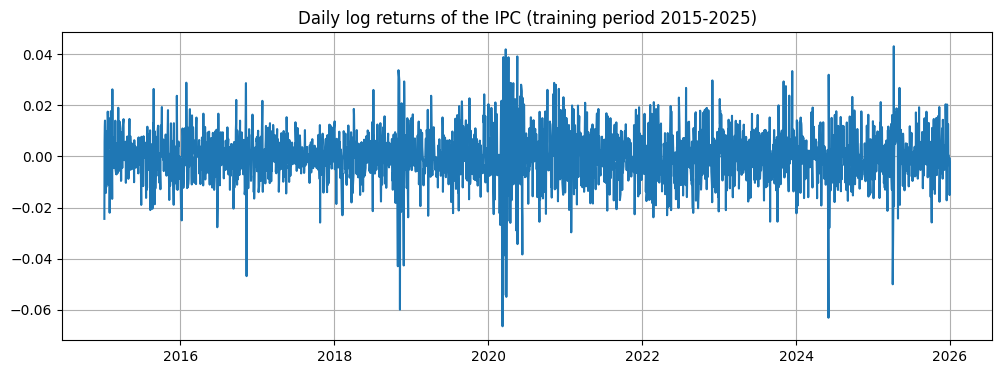

Date
2020-03-09    0.066381
2024-06-03    0.063051
2018-11-08    0.059884
2020-03-27    0.054889
2020-03-12    0.054235
Name: IPC, dtype: float64


In [22]:
ln_ipc = np.log(ipc)
ln_train_ipc = ln_ipc[:'2025-12-31']
ln_test_ipc = ln_ipc['2026-01-01':]

r_train_ipc = ln_train_ipc.diff().dropna()   # rendimientos logarítmicos diarios

plt.figure(figsize=(12, 4))
plt.plot(r_train_ipc.index, r_train_ipc)
plt.title('Daily log returns of the IPC (training period 2015-2025)')
plt.grid(True)
plt.show()

# los 5 rendimientos más extremos para revisar que no haya datos raros
print(r_train_ipc.abs().sort_values(ascending=False).head())

### 1.1 Estimación de la deriva y la volatilidad

Como el rendimiento diario es la deriva más un choque con media cero estimamos la deriva diaria con la media de los rendimientos y la volatilidad diaria con su desviación estándar, también comprobamos la deriva con la fórmula de último log precio menos el primero entre N-1.

Para pasarlos a términos anuales usamos 252 días hábiles la deriva se multiplica por 252 porque las medias se suman día con día y la volatilidad se multiplica por la raíz de 252 por la regla de la raíz cuadrada del tiempo.

In [23]:
phi0_ipc = float(r_train_ipc.mean())
sigma_ipc = float(r_train_ipc.std())
N_ipc = len(ln_train_ipc)

# comprobación: (último - primero)/(número de rendimientos)
phi0_ipc_check = float((ln_train_ipc.iloc[-1] - ln_train_ipc.iloc[0]) / (N_ipc - 1))

# términos anuales con 252 días hábiles
phi0_ipc_annual = phi0_ipc * 252
sigma_ipc_annual = sigma_ipc * np.sqrt(252)

print(f"Días de entrenamiento: {N_ipc}")
print(f"phi0 diaria  = {phi0_ipc:.6f}   (check: {phi0_ipc_check:.6f})")
print(f"sigma diaria = {sigma_ipc:.6f}")
print(f"phi0 anual   = {phi0_ipc_annual:.4f}  ({phi0_ipc_annual:.2%})")
print(f"sigma anual  = {sigma_ipc_annual:.4f}  ({sigma_ipc_annual:.2%})")

Días de entrenamiento: 2766
phi0 diaria  = 0.000153   (check: 0.000153)
sigma diaria = 0.009866
phi0 anual   = 0.0386  (3.86%)
sigma anual  = 0.1566  (15.66%)


**Interpretación 1.1**

La deriva diaria del IPC es 0.000153 y la volatilidad diaria es 0.009866, las dos formas de calcular la deriva dan lo mismo así que la estimación es correcta.

En términos anuales la deriva es de 3.86% y la volatilidad de 15.66% esto quiere decir que de 2015 a 2025 el IPC creció en promedio alrededor de 3.9% al año en términos logarítmicos pero con una variación de casi 16% al año, la volatilidad es aprox cuatro veces más grande que la deriva por lo que en un solo año el resultado depende mucho más de los choques que de la tendencia.

Comparado con el S&P 500 (8.6% de deriva y 20.1% de volatilidad) el IPC creció menos pero también fue menos volátil.

Los rendimientos más extremos del entrenamiento son de marzo de 2020 al inicio de la pandemia del COVID-19, de junio de 2024 después de las elecciones en México y de noviembre de 2018.

Ninguno pasa de 7% y coinciden con eventos del mercado por lo que no parecen errores en los datos además cada año tiene alrededor de 251 días con dato así que no faltan periodos.

### 1.2 Autocorrelación de rezago 1

Calculamos la autocorrelación de rezago 1 de los rendimientos diarios para ver si el rendimiento de ayer ayuda a predecir el de hoy, además la comparamos con el límite aproximado de más o menos 2 entre la raíz de n donde n es el número de rendimientos y si el valor absoluto de la autocorrelación es mayor a ese límite es estadísticamente distinta de cero con un nivel de confianza de alrededor del 95%.

In [24]:
ac1_ipc = float(r_train_ipc.autocorr(lag=1))
n_ret = len(r_train_ipc)
limite = 2 / np.sqrt(n_ret)

print(f"Autocorrelación lag-1: {ac1_ipc:.4f}")
print(f"Número de rendimientos: {n_ret}")
print(f"Límite aproximado ±2/sqrt(n): ±{limite:.4f}")
print(f"¿Estadísticamente distinta de cero?: {abs(ac1_ipc) > limite}")

Autocorrelación lag-1: 0.0291
Número de rendimientos: 2765
Límite aproximado ±2/sqrt(n): ±0.0380
¿Estadísticamente distinta de cero?: False


**Interpretación 1.2**

La autocorrelación de rezago 1 del IPC es 0.0291 y el límite aproximado con 2,765 rendimientos es de más o menos 0.038 y como 0.0291 es menor al límite no es estadísticamente distinta de cero que en otras palabras quiere decir que el rendimiento de ayer no ayuda a predecir el de hoy y esto es consistente con la hipótesis de caminata aleatoria.

A diferencia del S&P 500 donde la autocorrelación de -0.121 sí era significativa en el IPC no encontramos evidencia de que los rendimientos pasados ayuden a predecir los futuros.

## 2. Pronóstico Monte Carlo

### 2.1 Gráfica de abanico

Simulamos 5,000 trayectorias que empiezan en `yT_ipc`, el último log precio de 2025 y las que duran `h_ipc` días que son los días hábiles del periodo de prueba de 2026.

Cada trayectoria se construye con la suma acumulada de la deriva más choques normales con desviación estándar `sigma_ipc`, después calculamos los percentiles 5, 50 y 95 de cada día y los pasamos a escala de precio con `np.exp`.

En la gráfica ponemos el precio real de 2025, la banda del 90%, la mediana del pronóstico y el precio real de 2026 para comparar.

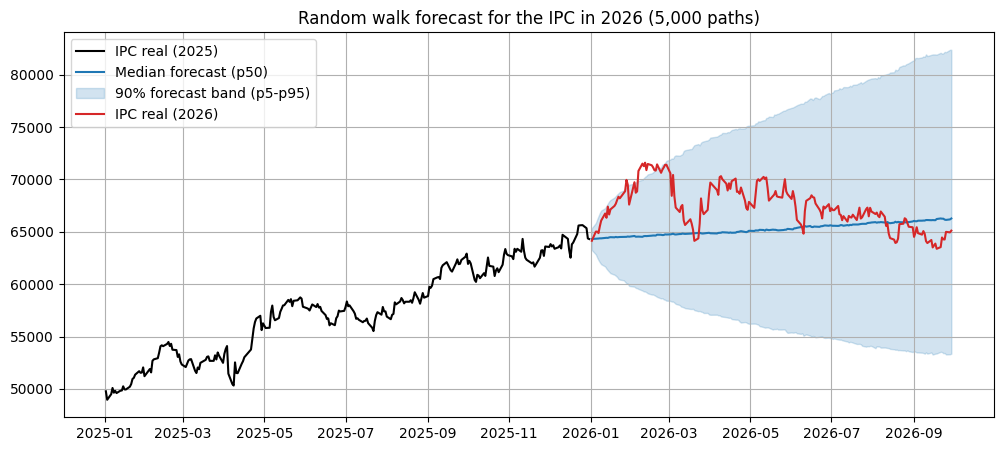

Días hábiles en el pronóstico: 187


In [25]:
yT_ipc = float(ln_train_ipc.iloc[-1])
h_ipc = len(ln_test_ipc)
n_paths_ipc = 5000

rng = np.random.default_rng(2026)
fc_ipc = yT_ipc + np.cumsum(phi0_ipc + rng.normal(0, sigma_ipc, size=(n_paths_ipc, h_ipc)), axis=1)
g05, g50, g95 = np.percentile(fc_ipc, [5, 50, 95], axis=0)

plt.figure(figsize=(12, 5))
plt.plot(ipc['2025-01-01':'2025-12-31'], color='black', label='IPC real (2025)')
plt.plot(ln_test_ipc.index, np.exp(g50), color='tab:blue', label='Median forecast (p50)')
plt.fill_between(ln_test_ipc.index, np.exp(g05), np.exp(g95), color='tab:blue', alpha=0.2, label='90% forecast band (p5-p95)')
plt.plot(ipc['2026-01-01':], color='tab:red', label='IPC real (2026)')
plt.title('Random walk forecast for the IPC in 2026 (5,000 paths)')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

print(f"Días hábiles en el pronóstico: {h_ipc}")

**Interpretación 2.1**

En la gráfica la banda del 90% se abre conforme avanzan los días ya que la incertidumbre crece con la raíz del número de días y al final del periodo va de alrededor de 53,000 a 82,000 puntos.

La mediana del pronóstico es casi una línea plana que sube muy poco desde 64,308 hasta alrededor de 66,000 porque la deriva del IPC es pequeña.

El IPC real de 2026 (línea roja) se queda dentro de la banda casi todo el periodo, en enero y febrero subió rápido hasta cerca de 71,000 y llegó al borde superior de la banda, después bajó poco a poco y terminó septiembre un poco por debajo de la mediana.

### 2.2 Probabilidad de terminar arriba del cierre de 2025

Calculamos la probabilidad de que el IPC termine el periodo de 2026 por encima de su cierre de 2025 de dos formas, con Monte Carlo que es la proporción de trayectorias cuyo último valor es mayor a `yT_ipc` y con la fórmula analítica usamos que el cambio en el log precio después de h días sigue una distribución normal con media h por la deriva y varianza h por la varianza del choque, entonces la probabilidad de que ese cambio sea positivo es la normal acumulada de h por la deriva entre la volatilidad por la raíz de h, que calculamos con `norm.cdf`.

In [26]:
end_ipc = fc_ipc[:, -1]

p_up_mc_ipc = float(np.mean(end_ipc > yT_ipc))
p_up_theory_ipc = float(norm.cdf(h_ipc * phi0_ipc / (sigma_ipc * np.sqrt(h_ipc))))

print(f"Cierre de 2025: {np.exp(yT_ipc):,.0f}")
print(f"P(IPC termina arriba del cierre de 2025): MC = {p_up_mc_ipc:.3f}, fórmula = {p_up_theory_ipc:.3f}")

Cierre de 2025: 64,308
P(IPC termina arriba del cierre de 2025): MC = 0.587, fórmula = 0.584


**Interpretación 2.2**

Tomamos la pregunta como la probabilidad de que el IPC termine 2026 arriba de su cierre de 2025 ya que la simulación es para 2026.

Con Monte Carlo la probabilidad de terminar arriba de 64,308 puntos es de 0.587 y con la fórmula es de 0.584 las dos casi coinciden y la diferencia de 0.003 es por usar un número limitado de trayectorias.

La probabilidad es mayor a 0.5 por la deriva positiva pero está cerca de 0.5 ya que la deriva es pequeña comparada con la volatilidad entonces el modelo casi no puede decir si el IPC va a subir o bajar si lo comparamos con la realidad el IPC sí terminó arriba con 65,111 puntos.

### 2.3 Percentil del valor real

Para saber si 2026 fue un periodo inusual calculamos en qué percentil de la distribución simulada cayó el valor real del último día disponible elcual es la proporción de trayectorias que terminaron por debajo del valor real, también calculamos la banda del 90% para ese día y si el valor real cae por debajo del percentil 5 o por arriba del 95 lo consideramos inusual según el modelo.

In [27]:
actual_end_ipc = float(ln_test_ipc.iloc[-1])
pct_actual_ipc = float(np.mean(end_ipc < actual_end_ipc))
low_ipc, high_ipc = np.exp(np.percentile(end_ipc, [5, 95]))

print(f"Último dato real: {ln_test_ipc.index[-1].date()}   nivel = {np.exp(actual_end_ipc):,.0f}")
print(f"Banda del 90% para ese día: {low_ipc:,.0f} a {high_ipc:,.0f}")
print(f"Percentil del valor real dentro de la simulación: {pct_actual_ipc:.2f}")

Último dato real: 2026-09-29   nivel = 65,111
Banda del 90% para ese día: 53,360 a 82,383
Percentil del valor real dentro de la simulación: 0.45


**Interpretación 2.3**

El último dato real es del 29 de septiembre de 2026 con 65,111 puntos y cae en el percentil 0.45 de la simulación es decir que el 45% de las trayectorias terminaron por debajo del valor real y quedó muy cerca de la mediana, como está dentro de la banda del 90% (de 53,360 a 82,383) según el modelo 2026 no fue un periodo inusual para el IPC aunque en febrero sí tuvo una subida fuerte que lo llevó al borde superior de la banda.

## 3. Raíz cuadrada del tiempo

El periodo de prueba de 2026 tiene menos de 252 días hábiles por lo que hacemos una simulación aparte de 5,000 trayectorias de 252 días con los mismos parámetros del IPC ya que aquí no comparamos contra datos reales y solo nos interesa cómo crece la incertidumbre.

Calculamos la desviación estándar del log precio simulado en el día 21 (alrededor de 1 mes) y en el día 252 (alrededor de 1 año), usamos los índices 20 y 251 porque Python empieza a contar desde 0, después calculamos su cociente y lo comparamos con la raíz de 252 entre 21, también imprimimos los valores teóricos los cualed son la volatilidad diaria por la raíz del número de días y la desviación a 21 días de la simulación de la pregunta 2 como comprobación.

In [28]:
rng = np.random.default_rng(252)
sim252 = yT_ipc + np.cumsum(phi0_ipc + rng.normal(0, sigma_ipc, size=(n_paths_ipc, 252)), axis=1)

sd21 = float(sim252[:, 20].std())        # día 21
sd252 = float(sim252[:, 251].std())      # día 252
sd21_main = float(fc_ipc[:, 20].std())   # día 21 en la simulación de la pregunta 2

print(f"SD a 21 días:  {sd21:.4f}   (simulación 2026: {sd21_main:.4f}, teoría: {sigma_ipc*np.sqrt(21):.4f})")
print(f"SD a 252 días: {sd252:.4f}   (teoría: {sigma_ipc*np.sqrt(252):.4f})")
print(f"Cociente SD252/SD21: {sd252/sd21:.3f}")
print(f"sqrt(252/21):        {np.sqrt(252/21):.3f}")
print(f"Cociente de varianzas: {(sd252/sd21)**2:.2f}")

SD a 21 días:  0.0444   (simulación 2026: 0.0452, teoría: 0.0452)
SD a 252 días: 0.1563   (teoría: 0.1566)
Cociente SD252/SD21: 3.524
sqrt(252/21):        3.464
Cociente de varianzas: 12.42


**Interpretación 3**

La desviación estándar del log precio simulado es 0.0444 a 21 días y 0.1563 a 252 días las cuales están muy cerca de los valores teóricos de 0.0452 y 0.1566 y la de 21 días de la simulación de la pregunta 2 da 0.0452 igual que la teoría.

El cociente entre las dos es 3.524 y la raíz de 252 entre 21 es 3.464 y son muy parecidos y la diferencia es por el error de muestreo de la simulación.

El cociente no es 12 porque lo que crece en proporción al tiempo es la varianza y no la desviación estándar y al sumar choques independientes se suman sus varianzas así que con 12 veces más días la varianza es 12 veces más grande (en la simulación da 12.42) pero la desviación estándar solo crece la raíz de 12 que es alrededor de 3.46 veces.

Esto significa que la incertidumbre a un año no es 12 veces la de un mes sino solo unas 3.5 veces.

## 4. Reflexión

Con nuestros resultados el IPC se comporta como una caminata aleatoria ya que la autocorrelación de 0.029 no es significativa así que el rendimiento de ayer no ayuda a predecir el de hoy y la deriva diaria de 0.000153 es muy pequeña comparada con la volatilidad diaria de 0.0099.

Para un modelo de IA que quiere predecir el precio de mañana esto significa que el mejor pronóstico sencillo es el precio de hoy más una deriva casi nula y que el error de ese pronóstico viene de choques que no se pueden anticipar con los precios pasados, por eso el modelo de IA tendría que demostrar que tiene un error de pronóstico menor que la caminata aleatoria con datos fuera de muestra (como nuestro periodo de prueba de 2026) y no solo con los datos con los que se entrenó además tendría que lograrlo de forma consistente en varios periodos y no por suerte y si no le gana a este pronóstico ingenuo el modelo no aporta nada aunque se vea bueno.